In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import pandas as pd
#from scipy.sparse import csr_array, lil_array
import matplotlib.pyplot as plt
import torch.nn as nn
#import time as tm
#from torch.func import jacrev, vmap
from tqdm import tqdm
from scipy.interpolate import BSpline
from scipy.integrate import solve_ivp
import sys
from typing import List
import os
sys.path.insert(0, '../../PopsCtrl/')
import function as my

# Set this to the number of physical cores you will use
num_threads = 10
tc.set_num_threads(num_threads)
tc.set_num_interop_threads(num_threads)
print(f"Threads set to: {tc.get_num_threads()}")

Threads set to: 10


In [2]:
Nqb = 2 #Number of qubits

nval = 2 #Number of states to be used for further validation. Won't be used during training
ThreeStates = False# USe it to implement or not the 3 initial states described in doi:10.1088/1367-2630/16/5/055012
loaded = False# Set True to load control fields from a file
filesctrl = "../../data_files/Control/StchKr_Had_1noi.csv"
FouFeat = True# Whether or not to use Fourier features

if (Nqb == 1):
  Liedim = 3#Dimension of the Lie-algebra
  nist = 7# NUmber of initial states
  Nfield=3# Number of control fields
  Nedo= Liedim*nist# Number of differential equations to solve
  Ncoll = 2#Number of collapse operators
else:
  Liedim = 15#Dimension of the Lie-algebra
  nist = 5# NUmber of initial states
  Nfield=6# Number of control fields
  Nedo= Liedim*nist# Number of differential equations to solve
  Ncoll = 4#Number of collapse operators

In [3]:
if loaded:
  loadedfields = pd.read_csv(filesctrl)

  t_points =  loadedfields.iloc[::2,0].to_numpy()
  dt = t_points[1]-t_points[0]
  t_points = t_points - 0.5*dt*np.ones_like(t_points)
  tfinal      = t_points[-1] + dt
  t_points = np.concatenate([t_points, np.array([tfinal])])
  N           = len(t_points)

  ctrls = loadedfields.iloc[::2,1:4].to_numpy()
  ctrls = np.concatenate([ctrls, np.zeros((1,Nfield))], axis=0)
  ctrls[-1,:] = 1.5*ctrls[-2,:] - 0.5*ctrls[-3,:]
else:
  tfinal = 2.#2.52*np.pi
  N = 101#Number of collocation points

  def Field(t):
      return ( 1.5* np.sin(2.0 * t) - 0.3*np.cos(3* t - 0.5) + 0.4*np.sin(7.0 * t)
          )*np.sin(np.pi*t/tfinal)**2

  np.random.seed(104711)# Use a seed for replicability of the results.

  ncoeff = 4# Number of coefficients in the expansion in Bspline functions

  def gen_rdn_Bsplines(t, knots, coeffs, degree=2):
      spline = BSpline(knots, coeffs, degree)
      return spline(t)

  t_points = np.linspace(0., tfinal, N)

  ctrls = np.zeros((len(t_points), Nfield))

  if (Nqb == 1):
      ctrls[:,0] = Field(t_points)
      if (Nfield > 1):
        ctrls[:,1] = np.cos(np.pi*t_points/tfinal)
        if (Nfield > 2):
            ctrls[:,2] = 0.5*(-1 + np.sin(np.pi*t_points/tfinal))
      #ctrls[:,1] = -0.5 * np.ones_like(t_points)
  else:
      degree=2
      internal_knots = np.linspace(0.0, tfinal, ncoeff - degree + 1)

      knots = np.r_[
          np.repeat(0.0, degree),
          internal_knots,
          np.repeat(tfinal, degree)
      ]

      a_free = np.random.uniform(-1, 1, (Nfield, ncoeff-2))  # Non-zero random coefficients for the B-spline
      coeffs = np.zeros((Nfield, ncoeff))
      coeffs[:, 1:-1] = a_free
      
      for i in range(Nfield):
        ctrls[:,i] = gen_rdn_Bsplines(t_points, knots, coeffs[i], degree=degree)

      def basis_values(t, knots=knots, degree=degree):
        """
        Return [B_0(t), B_1(t), ..., B_{ncoeff-1}(t)].
        
        If t is scalar: shape (ncoeff,)
        If t is an array: shape (len(t), ncoeff)
        """
        t_array = np.atleast_1d(t)

        Bmat = BSpline.design_matrix(
            t_array,
            knots,
            degree,
            extrapolate=False
        ).toarray()

        if np.ndim(t) == 0:
            return Bmat[0]

        return Bmat

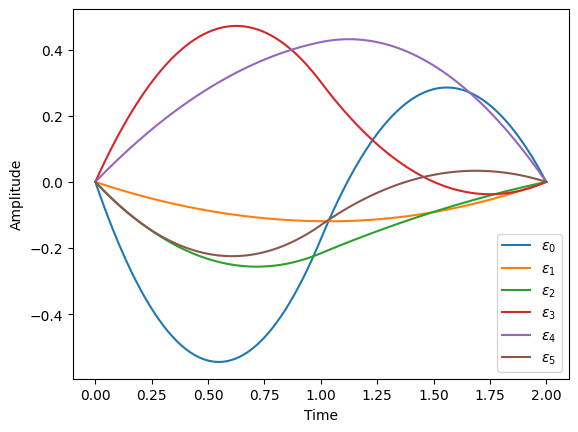

In [4]:
fig, ax = plt.subplots()
for i in range(Nfield):
  ax.plot(t_points, ctrls[:,i], label=fr"$\epsilon_{i}$")

ax.set_xlabel("Time")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

In [4]:
# Run this code to use the 3 initial states described in doi:10.1088/1367-2630/16/5/055012
if ThreeStates:
  d = 2**Nqb
  rho01 = qt.Qobj(np.diag([2*(d-i)/(d*(d+1)) for i in range(d)]))
  rho02 = qt.Qobj((1./d)*np.ones((d,d)))
  rho03 = (1./d)*qt.qeye(d)

  Instates = [rho01, rho02, rho03]
else:
  Instates = []
  # Define the set of initial states

  if (Nqb == 1):
      for _ in range(nist+nval):
          p = np.ones(3)
          while(np.sum(p*p) > 1.):
              p = np.random.uniform(-1., 1., 3)

          rho0 = qt.Qobj(0.5*np.array([[1.+p[2], p[0]-1j*p[1]],[p[0]+1j*p[1], 1.-p[2]]]))
          Instates.append(rho0)

  else:
      for i in range(2):
          for j in range(2):
              rho0 = qt.ket2dm(qt.tensor(qt.basis(2, i), qt.basis(2, j)))
              Instates.append(rho0)
      Instates.append( qt.Qobj(0.25*np.ones((4,4)), dims=[[2,2], [2,2]]))

In [5]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    # Uncomment the following code to use uniform frequency distribution and comment the code below it
    """
    def __init__(self, n_freq, f_max, trainable=True):
        super().__init__()
        self.f_max = f_max
        self.raw_freq = nn.Parameter(tc.randn(n_freq), requires_grad=trainable)

        f0 = tc.linspace(0.05 * f_max, 0.95 * f_max, n_freq)
        raw0 = inv_sigmoid(f0 / f_max)

        self.raw_freq = nn.Parameter(raw0.clone(), requires_grad=trainable)

    def get_freq(self):
        return self.f_max * tc.sigmoid(self.raw_freq)

    def forward(self, t):
        if t.dim() == 1:
            t = t.unsqueeze(1)   # (batch,1)

        freq = self.get_freq().unsqueeze(0)   # (1,n_freq)
        arg = 2.0 * np.pi * t * freq        # (batch,n_freq)

        return tc.cat([tc.sin(arg), tc.cos(arg)], dim=1)
    """
    def __init__(self, m, sigma=10.0, trainable=False):
        super().__init__()
        B = tc.randn(m, 1) * sigma
        self.B = nn.Parameter(B, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        x = 2 * np.pi * t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
    
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0, trainable=True):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            #self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=True)
            self.ff = FourierFeatures(m=n_freq, sigma=f_max, trainable=trainable)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater)**2)

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [6]:
if FouFeat:
        neuronio = [128, 128]

        X_vector = Rede(
        neuronio=neuronio,
        input_=1,
        output_=Nedo + Nfield,
        activation=[SIN()]*len(neuronio),
        creat_p=True,
        N_of_paramater=Ncoll,
        use_fourier=True,
        n_freq=12,
        f_max=1.0,
        trainable=False
        )

        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
else:
        neuronio = [256, 256]#[128,128,128] didn't work
        X_vector   = my.Rede(
        neuronio    = neuronio,
        input_      = 1,
        output_     = Nedo+Nfield,
        activation  =[tc.nn.Tanh()]*len(neuronio),
        creat_p     =True,
        N_of_paramater= Ncoll)
        opt = tc.optim.Adam(X_vector.parameters(),
                lr = 0.001)
        time =  tc.linspace(
                0,
                tfinal,
                N,
                dtype   = tc.float32,
                requires_grad = True).reshape((-1, 1))
        #index_data = np.random.randint(0,N,size=100)
        #X_vector.parametro

In [7]:
if (Nqb == 1):
    Sz = 0
    gams = [0.03, 0.05]#Decay rates for the Lindblad operators

    basis = [qt.sigmax(), qt.sigmay(), qt.sigmaz()]

    # The full Hamiltonian is defined as a list: 
    H = [basis[2]*Sz]
    for i in range(Nfield):
        H.append([basis[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data

    c_ops = [np.sqrt(gams[0])*qt.sigmaz(), np.sqrt(gams[1])*qt.sigmam()]

    opts = {'store_states':True, 'atol':1.e-8, 'rtol':1.e-6}

    Obsdat = []

    # Define the set of initial states
    for i in range(len(Instates)):
        result = qt.mesolve(H, rho0=Instates[i], tlist=t_points, e_ops=basis, c_ops=c_ops, options=opts)
        Obsdat.append(result.expect)

    Odata = tc.tensor(np.array(Obsdat[:nist]).reshape(Nedo, N).T, dtype=time.dtype)
else:
    #Decay rates for the Lindblad operators
    gams = [0.05, 0.03, 0.05, 0.03]
    bas1q = [qt.qeye(2), qt.sigmax(), qt.sigmay(), qt.sigmaz()]
    bas2q = []
    for i in range(4):
        for j in range(4):
            if (i+j) != 0:
                bas2q.append(qt.tensor(bas1q[i], bas1q[j]))

    # The full Hamiltonian is defined as a list: 
    H = [qt.tensor(bas1q[1], bas1q[1]) + qt.tensor(bas1q[2], bas1q[2]) + qt.tensor(bas1q[3], bas1q[3])]

    for i in range(3):
        H.append([bas2q[i], ctrls[:, i]]) # QuTiP uses cubic spline interpolation for field_data

    for i in range(3):
        H.append([qt.tensor(bas1q[i+1], qt.qeye(2)), ctrls[:, i+3]])

    c_ops = [np.sqrt(gams[0])*qt.tensor(qt.sigmam(), qt.qeye(2)),
            np.sqrt(gams[1])*qt.tensor(qt.sigmaz(), qt.qeye(2)),
            np.sqrt(gams[2])*qt.tensor(qt.qeye(2) , qt.sigmam()),
            np.sqrt(gams[3])*qt.tensor(qt.qeye(2) , qt.sigmaz()),]

    opts = {'store_states':True, 'atol':1.e-11, 'rtol':1.e-9}

    Obsdat = []

    # Define the set of initial states
    for i in range(len(Instates)):
        result = qt.mesolve(H, rho0=Instates[i], tlist=t_points, e_ops=bas2q, c_ops=c_ops, options=opts)
        Obsdat.append(result.expect)

    Odata = tc.tensor(np.array(Obsdat[:nist]).reshape(Nedo, N).T, dtype=time.dtype)

Now, I try to compute the sensitivities

$
S_p(t) = \frac{\partial \rho(t)}{\partial \theta_p},
$

where $\theta_p$ are either coefficients of the BSpline functions in the control fields or decay rates. I compute sensitivities by solving the differential equations

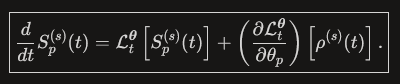

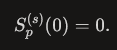

It is necessary to buil the Liouvillians and to vectorize the master equation.

In [8]:
def commutator_super(A):
    """Superoperator rho -> -i [A, rho]."""
    return -1j * (qt.spre(A) - qt.spost(A))

dec_ops = [qt.tensor(qt.sigmam(), qt.qeye(2)),
qt.tensor(qt.sigmaz(), qt.qeye(2)),
qt.tensor(qt.qeye(2) , qt.sigmam()),
qt.tensor(qt.qeye(2) , qt.sigmaz()),]

D_ops_qutip = [qt.lindblad_dissipator(L) for L in dec_ops]

L0 = commutator_super(H[0]).full()

L_controls = [
    commutator_super(H[j+1][0]).full()
    for j in range(Nfield)
]

D_ops = [
    Dq.full()
    for Dq in D_ops_qutip
]

basis_vals = basis_values(t_points, knots=knots, degree=degree)
basis_vals.shape

(101, 4)

In [ ]:
def controls_from_bspline(t, a, basis_values):
    """
    a: array with shape (6, m)
    basis_values(t): returns array B(t) with shape (m,)
    """
    B_t = basis_values(t)
    return a @ B_t

def liouvillian_matrix(t, a, gamma, basis_values):
    """
    Returns the d^2 x d^2 Liouvillian matrix L(t).

    a      : shape (6, m), B-spline coefficients
    gamma  : shape (n_gamma,), constant decay rates
    """
    u_t = controls_from_bspline(t, a, basis_values)

    L_t = L0.copy()

    for q, uq in enumerate(u_t):
        L_t = L_t + uq * L_controls[q]

    for ell, gamma_ell in enumerate(gamma):
        L_t = L_t + gamma_ell * D_ops[ell]

    return L_t

def dL_da(t, q, r, basis_values):
    """
    dL(t) / d a[q, r].
    """
    B_t = basis_values(t)
    return B_t[r] * L_controls[q]

def dL_dgamma(ell):
    """
    dL(t) / d gamma[ell].
    """
    return D_ops[ell]

def vec(qobj):
    """Qobj operator -> complex vector with QuTiP column-stacking convention."""
    return qt.operator_to_vector(qobj).full().ravel()

def unvec(v, dims=[[2, 2], [2, 2]]):
    """Complex vector -> density-matrix Qobj."""
    return qt.vector_to_operator(
        qt.Qobj(v.reshape((-1, 1)), dims=[dims, [1]])
    )

"""
def rhs_rho(t, rho_vec, a, gamma, basis_values):
    L_t = liouvillian_matrix(t, a, gamma, basis_values)
    return L_t @ rho_vec

rho0_vec = vec(Instates[-1]).astype(complex)

solution = solve_ivp(
    fun=lambda t, y: rhs_rho(t, y, coeffs, gams, basis_values),
    t_span=(0.0, tfinal),
    y0=rho0_vec,
    t_eval=t_points,
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
)
rho_scipy = [
    qt.vector_to_operator(
        qt.Qobj(
            solution.y[:, j].reshape((-1, 1)),
            dims=[rho0.dims, [1]]
        )
    )
    for j in range(len(t_points))
]

errors = np.array([
    (rho_scipy[j] - result.states[j]).norm("fro")
    for j in range(len(t_points))
])
"""

In [10]:
def rhs_state_and_sensitivities(t, y, a, gamma, basis_values):
    """
    y = [rho_vec, S_0_vec, ..., S_{P-1}_vec].

    Each block has length d2 = d*d.
    """
    d2 = L0.shape[0]
    n_params = Nfield * ( a.shape[1] - 2 ) + len(gams)

    rho_vec = y[:d2]
    sens_vecs = y[d2:].reshape(n_params, d2)

    L_t = liouvillian_matrix(t, a, gamma, basis_values)

    dy = np.empty_like(y, dtype=complex)

    # Physical density-matrix evolution.
    dy[:d2] = L_t @ rho_vec

    # Sensitivity evolution.
    dsens = np.empty_like(sens_vecs, dtype=complex)

    p = 0

    # Parameters a[q, r], skipping the endpoints.
    for q in range(Nfield):
        for r in range(1, a.shape[1]-1):
            dL_p = dL_da(t, q, r, basis_values)
            dsens[p] = L_t @ sens_vecs[p] + dL_p @ rho_vec
            p += 1

    # Parameters gamma[ell].
    for ell in range(len(gamma)):
        dL_p = dL_dgamma(ell)
        dsens[p] = L_t @ sens_vecs[p] + dL_p @ rho_vec
        p += 1

    dy[d2:] = dsens.ravel()
    return dy

In [20]:
print(solsens.y.shape, jacobian_at_t.shape)

(272, 101) (15, 16)


In [11]:
d2 = L0.shape[0]
n_params = Nfield * ( coeffs.shape[1] - 2 ) + len(gams)

y0 = np.zeros((n_params + 1) * d2, dtype=complex)

J_all = [[] for _ in range(len(t_points))]

for st in Instates:
    rho0_vec = vec(st).astype(complex)
    y0[:d2] = rho0_vec
    solsens = solve_ivp(
        fun=lambda t, y: rhs_state_and_sensitivities(
            t, y, coeffs, gams, basis_values
        ),
        t_span=(0.0, tfinal),
        y0=y0,
        t_eval=t_points,
        method="DOP853",
        rtol=1e-9,
        atol=1e-11,
    )
    obs_rows = np.vstack([
        vec(O.dag()).conj()
        for O in bas2q
    ])
    J_stacked = []
    for time_index in range(len(t_points)):
        rho_vec_t = solsens.y[:d2, time_index]
        sens_t = solsens.y[d2:, time_index].reshape(n_params, d2)

        expectations = obs_rows @ rho_vec_t                 # shape (15,)
        jacobian_at_t = obs_rows @ sens_t.T                 # shape (15, n_params)
        J_stacked.append(jacobian_at_t[:,:Nfield*(ncoeff-2)])

    for time_index, jacobian_at_t in enumerate(J_stacked):
        J_all[time_index].append(jacobian_at_t)

J_all = [np.vstack(J_time) for J_time in J_all]

In [12]:
condnums = np.zeros_like(t_points)
for i in range(len(t_points)):
  singvals = np.linalg.svdvals(J_all[i])
  condnums[i] = np.max(singvals) / np.min(singvals)

/tmp/ipykernel_133067/1719528795.py:4: RuntimeWarning: invalid value encountered in scalar divide
  condnums[i] = np.max(singvals) / np.min(singvals)


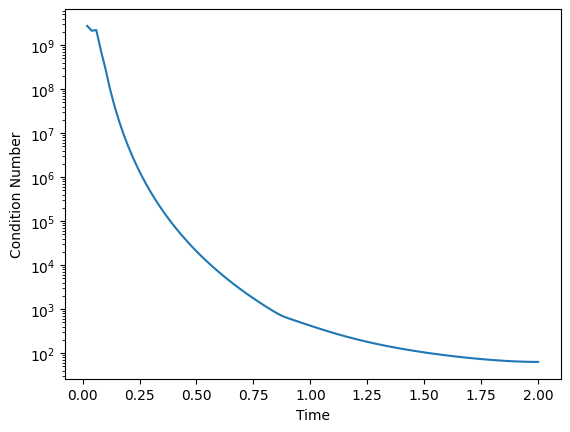

In [13]:
fig, ax = plt.subplots()

ax.semilogy(t_points,  condnums)

ax.set_xlabel("Time")
ax.set_ylabel("Condition Number")

plt.show()

In [ ]:
if (Nqb==1):
    def calculate_physics_loss(commcoeff: tc.Tensor, collcoef: tc.Tensor, cnstcoef: tc.Tensor, Gammas: tc.Tensor, Obs: tc.Tensor, derivs: tc.Tensor, Jt: List[tc.Tensor]):
        dim = Jt.shape[1]
        Nist = int(derivs.shape[1]/dim)
        #-----Calculate the matrix corresponding to the right-hand side of the EDOs----------------
        A = tc.tensordot(Jt, commcoeff, dims=([1], [0])) + tc.tensordot(Gammas, collcoef, dims=([0], [0]))
        b = Gammas @ cnstcoef
        rhs_vec = tc.zeros_like(derivs)

        for i in range(Nist):
            rhs_vec[:, i*dim:(i+1)*dim] = b + tc.bmm(A, Obs[:, i*dim:(i+1)*dim].unsqueeze(-1)).squeeze(-1)
        # Residual squared, summed over all components
        loss_edo = ((derivs - rhs_vec)**2).mean()
        
        return loss_edo

else:
    
    def calculate_physics_loss(dX_dt: tc.Tensor, Jctrl: tc.Tensor, Jcnst: tc.Tensor, Gammas: tc.Tensor, Obs: tc.Tensor):
        gamma1, gamma2, gamma3, gamma4 = Gammas
        JIX,JIY,JIZ,JXI,JYI,JZI = Jctrl[:,0:1], Jctrl[:,1:2], Jctrl[:,2:3], Jctrl[:,3:4], Jctrl[:,4:5], Jctrl[:,5:6],
        JXX,JXY,JXZ,JYX,JYY,JYZ,JZX,JZY,JZZ = Jcnst
        IX,IY,IZ,XI,XX,XY,XZ,YI = Obs[:,0:1], Obs[:,1:2], Obs[:,2:3], Obs[:,3:4], Obs[:,4:5], Obs[:,5:6], Obs[:,6:7], Obs[:,7:8]
        YX,YY,YZ,ZI,ZX,ZY,ZZ = Obs[:,8:9], Obs[:,9:10], Obs[:,10:11], Obs[:,11:12], Obs[:,12:13], Obs[:,13:14], Obs[:,14:15]

        LOSS_edo = (dX_dt[:,0:1] - ( +IX*(-0.5*gamma3 - 2.0*gamma4) +IY*(-1.0*JIZ) +IZ*(1.0*JIY) +(-1.0*JXZ)*XY +JXY*XZ +(-1.0*JYZ)*YY +(1.0*JYY)*YZ +(-1.0*JZZ)*ZY +(1.0*JZY)*ZZ))**2
        LOSS_edo += (dX_dt[:,1:2] - ( +IX*(1.0*JIZ) +IY*(-0.5*gamma3 - 2.0*gamma4) +IZ*(-1.0*JIX) +(1.0*JXZ)*XX +(-1.0*JXX)*XZ +JYZ*YX +(-1.0*JYX)*YZ +(1.0*JZZ)*ZX +(-1.0*JZX)*ZZ))**2
        LOSS_edo += (dX_dt[:,2:3] - ( (-1.0*gamma3) +IX*(-1.0*JIY) +IY*(1.0*JIX) +IZ*(-1.0*gamma3) +(-1.0*JXY)*XX +(1.0*JXX)*XY +(-1.0*JYY)*YX +JYX*YY +(-1.0*JZY)*ZX +(1.0*JZX)*ZY))**2
        LOSS_edo += (dX_dt[:,3:4] - ( +XI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*JZI)*YI +(-1.0*JZX)*YX +(-1.0*JZY)*YY +(-1.0*JZZ)*YZ +(1.0*JYI)*ZI +JYX*ZX +(1.0*JYY)*ZY +(1.0*JYZ)*ZZ))**2
        LOSS_edo += (dX_dt[:,4:5] - ( +IY*(-1.0*JXZ) +IZ*(1.0*JXY) +XX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*XY +JIY*XZ +(-1.0*JZX)*YI +(-1.0*JZI)*YX +(1.0*JYX)*ZI +JYI*ZX))**2
        LOSS_edo += (dX_dt[:,5:6] - ( +IX*(1.0*JXZ) +IZ*(-1.0*JXX) +(1.0*JIZ)*XX +XY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*XZ +(-1.0*JZY)*YI +(-1.0*JZI)*YY +(1.0*JYY)*ZI +JYI*ZY))**2
        LOSS_edo += (dX_dt[:,6:7] - ( +IX*(-1.0*JXY) +IY*(1.0*JXX) +XI*(-1.0*gamma3) +(-1.0*JIY)*XX +(1.0*JIX)*XY +XZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*JZZ)*YI +(-1.0*JZI)*YZ +(1.0*JYZ)*ZI +(1.0*JYI)*ZZ))**2
        LOSS_edo += (dX_dt[:,7:8] - ( +(1.0*JZI)*XI +(1.0*JZX)*XX +JZY*XY +(1.0*JZZ)*XZ +YI*(-0.5*gamma1 - 2.0*gamma2) +(-1.0*JXI)*ZI +(-1.0*JXX)*ZX +(-1.0*JXY)*ZY +(-1.0*JXZ)*ZZ))**2
        LOSS_edo += (dX_dt[:,8:9] - ( +IY*(-1.0*JYZ) +IZ*(1.0*JYY) +(1.0*JZX)*XI +(1.0*JZI)*XX +YX*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*YY +JIY*YZ +(-1.0*JXX)*ZI +(-1.0*JXI)*ZX))**2
        LOSS_edo += (dX_dt[:,9:10] - ( +IX*JYZ +IZ*(-1.0*JYX) +JZY*XI +(1.0*JZI)*XY +(1.0*JIZ)*YX +YY*(-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*YZ +(-1.0*JXY)*ZI +(-1.0*JXI)*ZY))**2
        LOSS_edo += (dX_dt[:,10:11] - ( +IX*(-1.0*JYY) +IY*JYX +(1.0*JZZ)*XI +(1.0*JZI)*XZ +YI*(-1.0*gamma3) +(-1.0*JIY)*YX +(1.0*JIX)*YY +YZ*(-0.5*gamma1 - 2.0*gamma2 - 1.0*gamma3) +(-1.0*JXZ)*ZI +(-1.0*JXI)*ZZ))**2
        LOSS_edo += (dX_dt[:,11:12] - ( (-1.0*gamma1) +(-1.0*JYI)*XI +(-1.0*JYX)*XX +(-1.0*JYY)*XY +(-1.0*JYZ)*XZ +(1.0*JXI)*YI +(1.0*JXX)*YX +JXY*YY +(1.0*JXZ)*YZ +ZI*(-1.0*gamma1)))**2
        LOSS_edo += (dX_dt[:,12:13] - ( +IX*(-1.0*gamma1) +IY*(-1.0*JZZ) +IZ*(1.0*JZY) +(-1.0*JYX)*XI +(-1.0*JYI)*XX +(1.0*JXX)*YI +(1.0*JXI)*YX +ZX*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIZ)*ZY +(1.0*JIY)*ZZ))**2
        LOSS_edo += (dX_dt[:,13:14] - ( +IX*(1.0*JZZ) +IY*(-1.0*gamma1) +IZ*(-1.0*JZX) +(-1.0*JYY)*XI +(-1.0*JYI)*XY +JXY*YI +(1.0*JXI)*YY +(1.0*JIZ)*ZX +ZY*(-1.0*gamma1 - 0.5*gamma3 - 2.0*gamma4) +(-1.0*JIX)*ZZ))**2
        LOSS_edo += (dX_dt[:,14:15] - ( +IX*(-1.0*JZY) +IY*(1.0*JZX) +IZ*(-1.0*gamma1) +(-1.0*JYZ)*XI +(-1.0*JYI)*XZ +(1.0*JXZ)*YI +(1.0*JXI)*YZ +ZI*(-1.0*gamma3) +(-1.0*JIY)*ZX +(1.0*JIX)*ZY +ZZ*(-1.0*gamma1 - 1.0*gamma3)))**2
        LOSS_edo = LOSS_edo.mean() 

        return LOSS_edo

    #calculate_physics_loss = tc.compile(calculate_physics_loss)